# 메챠 카멜레온 · YOLO 입문 실습 노트북

**목적:** 지금까지 터미널에서 한 작업(환경 확인 → YOLO 설치 확인 → 버스 이미지 탐지 → 게임 스크린샷 탐지)을 **코드와 출력 결과를 함께 기록**하기.

- 이 파일을 **`camo-score` 프로젝트 폴더 안에** 저장한 뒤 VS Code에서 여세요.
- 오른쪽 위 **Select Kernel**에서 앞서 만든 **`camo-yolo` Conda 환경**을 선택하세요.
- 셀은 `Shift + Enter`로 실행합니다.
- 아직 게임 캐릭터 탐지 모델을 학습하지 않았으므로 **기본 모델이 캐릭터를 인식하지 못하는 것은 정상**입니다.

이 노트북은 팀의 YOLO 담당 브랜치에서 실험 과정을 기록하는 용도입니다.

## STEP 1. 현재 Python 환경 확인

**왜 필요한가?** 앞서 Anaconda `base`에 NumPy 버전 충돌이 있었으므로, 이 노트북이 실제로 `camo-yolo` 환경을 사용하고 있는지 먼저 확인합니다.

아래 출력의 Python 경로에 `envs\camo-yolo`가 포함되는지 확인하세요. 아니라면 **코드를 더 실행하지 말고** VS Code의 커널 선택 메뉴에서 환경을 변경하세요.

In [1]:
import sys
from pathlib import Path

print("실행 중인 Python:", sys.executable)
print("Python 버전:", sys.version.split()[0])

if "camo-yolo" not in sys.executable.lower():
    print("⚠️ 주의: 앞에서 만든 camo-yolo 환경이 아닐 수 있습니다. 커널을 확인하세요.")
else:
    print("✅ camo-yolo 환경 확인")

실행 중인 Python: c:\Users\user\anaconda3\envs\camo-yolo\python.exe
Python 버전: 3.11.18
✅ camo-yolo 환경 확인


## STEP 2. 필요한 라이브러리 설치 또는 확인

**`%pip`은 Jupyter Notebook에서 쓰는 설치 명령어**로, 현재 노트북 커널의 Python 환경에 패키지를 설치합니다. 터미널의 `pip install`과 목적은 같지만 코드 셀과 실행 기록이 남습니다.

**주의:** STEP 1에서 `camo-yolo`가 선택된 것을 확인한 뒤에만 실행하세요. 이미 설치되어 있으면 다시 설치하지 않아도 됩니다. 패키지를 새로 설치한 경우 커널 재시작이 필요할 수 있습니다.

In [ ]:
# 설치가 이미 완료되어 있다면 이 셀은 건너뛰어도 됩니다.
# Jupyter 전용 매직 명령어: 현재 커널에 설치합니다.
%pip install ultralytics opencv-python matplotlib

In [2]:
import numpy as np
import cv2
import torch
import ultralytics
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("CUDA 사용 가능:", torch.cuda.is_available())
print("✅ 라이브러리 import 성공")

NumPy: 2.4.6
OpenCV: 5.0.0
PyTorch: 2.15.0+cpu
Ultralytics: 8.4.210
CUDA 사용 가능: False
✅ 라이브러리 import 성공


## STEP 3. 프로젝트 폴더 구성

**왜 필요한가?** `samples`에는 원본 이미지, `outputs`에는 이번 실습에서 저장한 탐지 결과, `detector`에는 추후 YOLO 코드, `dataset`에는 나중에 학습용 이미지를 둡니다.

`runs`는 YOLO의 자동 저장 경로로 쓰일 수 있지만, **`runs` 아래에 프로젝트를 만들 필요는 없습니다.**

> 이 노트북이 `camo-score` 폴더 안에서 실행 중이라는 가정입니다. 아래 `ROOT` 출력이 실제 프로젝트 폴더와 다르면 `ROOT`를 정확한 경로로 수정하세요.

In [3]:
from pathlib import Path

ROOT = Path.cwd()  # Jupyter의 현재 작업 디렉터리
# 필요 시 아래처럼 수정: ROOT = Path(r"C:\Users\user\Desktop\camo-score")

for folder in ["samples", "outputs", "detector", "dataset/images/train", "dataset/images/val", "dataset/images/test", "dataset/labels/train", "dataset/labels/val", "dataset/labels/test"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

print("프로젝트 폴더:", ROOT.resolve())
for folder in ["samples", "outputs", "detector", "dataset"]:
    print(" -", ROOT / folder)

프로젝트 폴더: C:\Users\user\Desktop\camo-score
 - c:\Users\user\Desktop\camo-score\samples
 - c:\Users\user\Desktop\camo-score\outputs
 - c:\Users\user\Desktop\camo-score\detector
 - c:\Users\user\Desktop\camo-score\dataset


## STEP 4. YOLO 사전학습 모델 불러오기

**YOLO26 Nano (`yolo26n.pt`)**는 일반적인 물체를 찾도록 미리 학습된 가벼운 탐지 모델입니다. `YOLO(...)`는 그 모델의 가중치 파일을 메모리에 불러오는 코드입니다.

첫 실행 시 가중치 파일이 인터넷에서 다운로드될 수 있습니다. **아직 메챠 카멜레온 전용 모델은 아닙니다.**

In [4]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")
print("모델 작업 종류:", model.task)
print("클래스 수:", len(model.names))
print("✅ 사전학습 모델 로딩 완료")

모델 작업 종류: detect
클래스 수: 80
✅ 사전학습 모델 로딩 완료


## STEP 5. 공식 예제 이미지 `bus.jpg` 탐지하기

이 셀은 이전에 터미널에서 실행했던 `yolo predict model=yolo26n.pt`를 **Python 코드로 다시 실행**하는 것입니다.

- `source`: 어떤 이미지를 분석할지 정합니다.
- `conf=0.25`: 신뢰도가 0.25 미만인 예측은 표시하지 않습니다.
- `results[0]`: 첫 이미지의 탐지 결과입니다.
- `result.plot()`: 탐지 상자가 그려진 이미지(BGR)를 반환합니다.

별도 터미널 명령 없이 결과 이미지를 **노트북 화면에 바로 표시하고 파일로도 저장**합니다.

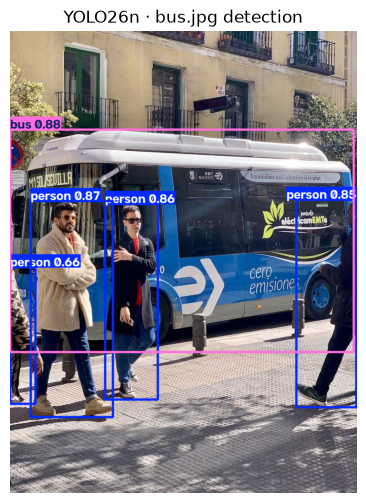

결과 저장: c:\Users\user\Desktop\camo-score\outputs\bus_detected.jpg
탐지된 물체 수: 5


In [5]:
import matplotlib.pyplot as plt

bus_url = "https://ultralytics.com/images/bus.jpg"
results = model.predict(source=bus_url, conf=0.25, verbose=False)
bus_result = results[0]

# 탐지 결과를 이미지에 그리기
bus_annotated = bus_result.plot()

# 이번 실습 결과를 원하는 폴더에 저장
bus_output = ROOT / "outputs" / "bus_detected.jpg"
cv2.imwrite(str(bus_output), bus_annotated)

# OpenCV는 BGR, matplotlib은 RGB를 사용하므로 변환
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(bus_annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("YOLO26n · bus.jpg detection")
plt.show()

print("결과 저장:", bus_output)
print("탐지된 물체 수:", len(bus_result.boxes))

## STEP 6. 탐지 결과를 숫자로 읽어보기

YOLO는 그림만 만드는 모델이 아닙니다. **각 객체의 종류, 박스 좌표, 탐지 신뢰도**를 데이터로 반환합니다. 이 정보가 나중에 점수 알고리즘 팀원에게 전달될 값입니다.

- `xyxy` → `[왼쪽 x, 위쪽 y, 오른쪽 x, 아래쪽 y]` (픽셀 좌표)
- `conf` → 탐지 신뢰도 (실제 정답 확률과 동일하지 않음)
- `cls` → 객체 종류의 번호

In [6]:
detected_objects = []
for box in bus_result.boxes:
    cls_id = int(box.cls[0].item())
    detected_objects.append({
        "class_id": cls_id,
        "class_name": bus_result.names[cls_id],
        "bbox": [round(v, 1) for v in box.xyxy[0].tolist()],
        "confidence": round(float(box.conf[0].item()), 3),
    })

for item in detected_objects:
    print(item)

{'class_id': 5, 'class_name': 'bus', 'bbox': [0.0, 230.5, 803.2, 750.7], 'confidence': 0.881}
{'class_id': 0, 'class_name': 'person', 'bbox': [48.6, 397.7, 240.3, 902.4], 'confidence': 0.872}
{'class_id': 0, 'class_name': 'person', 'bbox': [222.9, 404.8, 345.5, 861.0], 'confidence': 0.861}
{'class_id': 0, 'class_name': 'person', 'bbox': [669.6, 394.5, 809.9, 879.4], 'confidence': 0.846}
{'class_id': 0, 'class_name': 'person', 'bbox': [0.2, 553.0, 59.7, 871.3], 'confidence': 0.656}


## STEP 7. 메챠 카멜레온 스크린샷 테스트

게임 스크린샷을 `camo-score/samples/test.png`라는 이름으로 저장하세요. 그 다음 아래 셀을 실행하면 됩니다.

**아직 전용 학습 전이므로 캐릭터를 찾지 못하거나 엉뚱한 클래스로 분류해도 정상입니다.** 이런 결과를 기록해 두면 추후 파인튜닝 전후 비교 자료가 됩니다.

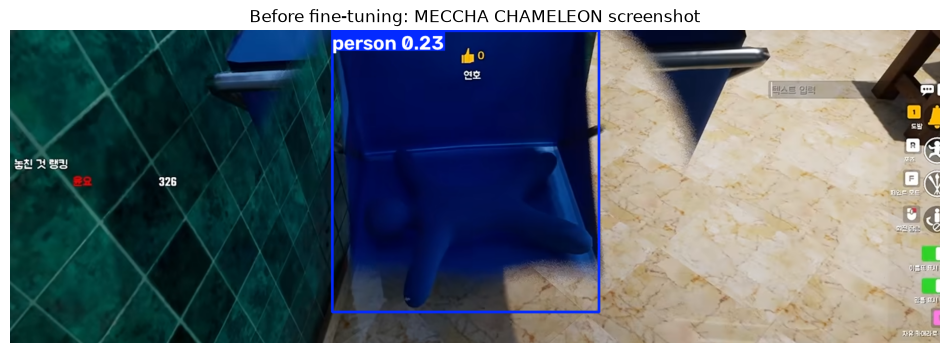

저장 위치: c:\Users\user\Desktop\camo-score\outputs\game_before_training.jpg
탐지된 후보 수: 1
{'class_name': 'person', 'confidence': 0.228, 'bbox': [639, 0, 1168, 558]}


In [7]:
game_image = ROOT / "samples" / "test.png"

if not game_image.is_file():
    print("⚠️ 스크린샷이 없습니다:", game_image)
    print("samples 폴더에 게임 이미지를 test.png라는 이름으로 넣고 이 셀을 다시 실행하세요.")
else:
    game_results = model.predict(source=str(game_image), conf=0.15, verbose=False)
    game_result = game_results[0]
    game_annotated = game_result.plot()
    game_output = ROOT / "outputs" / "game_before_training.jpg"
    cv2.imwrite(str(game_output), game_annotated)

    plt.figure(figsize=(12, 7))
    plt.imshow(cv2.cvtColor(game_annotated, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title("Before fine-tuning: MECCHA CHAMELEON screenshot")
    plt.show()

    print("저장 위치:", game_output)
    print("탐지된 후보 수:", len(game_result.boxes))
    for box in game_result.boxes:
        cls_id = int(box.cls[0].item())
        print({"class_name": game_result.names[cls_id],
               "confidence": round(float(box.conf[0].item()), 3),
               "bbox": [int(v) for v in box.xyxy[0].tolist()]})

## STEP 8. YOLO 담당자가 팀에 제공할 함수 형태 (학습 후 사용)

아래는 **앞으로 만들 최종 함수의 인터페이스 예시**입니다. 지금은 `best.pt`가 없으므로 실행하지 않습니다.

- 입력: 스크린샷 파일 경로 또는 이미지
- 출력: `bbox`, `confidence`, `class_id`로 이루어진 리스트
- 탐지 실패: 빈 리스트 `[]`

**주의:** Detection 모델의 박스는 캐릭터의 정확한 윤곽 마스크가 아닙니다. 점수 계산에 필요한 마스크는 별도 라벨링/수동 입력 또는 Segmentation 기능으로 확보해야 합니다.

In [8]:
# 아래 코드는 학습 후 best.pt가 생성되면 실행하는 예시입니다.
# 지금은 함수 구조만 읽고, 실제 데이터셋 구축 후 사용하세요.

def detect_chameleon(image_path, weight_path=None, conf=0.15):
    if weight_path is None:
        weight_path = ROOT / "runs" / "detect" / "camo_v1" / "weights" / "best.pt"
    if not Path(weight_path).exists():
        raise FileNotFoundError("학습된 best.pt가 없습니다. 모델 학습 후 실행하세요.")

    custom_model = YOLO(str(weight_path))
    result = custom_model.predict(source=str(image_path), conf=conf, verbose=False)[0]
    return [
        {
            "bbox": [int(v) for v in box.xyxy[0].tolist()],
            "confidence": float(box.conf[0].item()),
            "class_id": int(box.cls[0].item()),
        }
        for box in result.boxes
    ]

print("✅ 팀원에게 제공할 함수 인터페이스 정의 완료 (아직 학습 전)")

✅ 팀원에게 제공할 함수 인터페이스 정의 완료 (아직 학습 전)


## STEP 9. 실습 기록 및 다음 할 일

### 이번 노트북에서 확인할 완료 조건

- [ ] `sys.executable`에 `camo-yolo` 환경이 표시된다.
- [ ] `ultralytics`, `numpy`, `cv2`, `torch`를 정상 import했다.
- [ ] `yolo26n.pt` 모델을 불러왔다.
- [ ] 버스 이미지에 박스가 표시되고 `outputs/bus_detected.jpg`가 생성되었다.
- [ ] `results[0].boxes`로 클래스·좌표·신뢰도를 출력했다.
- [ ] `samples/test.png`를 넣어 게임 이미지 예측을 실행했다.

### 다음 개발 단계

1. 메챠 카멜레온 게임 스크린샷을 다양하게 수집합니다.
2. CVAT에서 **`chameleon` 1개 클래스**로 Bounding Box를 라벨링합니다.
3. `dataset/images/{train,val,test}` 및 `dataset/labels/{train,val,test}`에 데이터를 분리합니다.
4. `dataset/data.yaml`을 준비하고 `model.train(...)`으로 전용 모델을 추가 학습합니다.
5. `best.pt`로 새로운 게임 스크린샷을 탐지하고, 결과를 점수 알고리즘 담당자에게 전달합니다.

**공식 문서:** [Ultralytics Python 사용법](https://docs.ultralytics.com/usage/python) / [JupyterLab 사용법](https://docs.ultralytics.com/integrations/jupyterlab)